# Φάση 2 · Task 1: Σύγκριση μεθόδων Feature Selection (k = 1…100)

Μέθοδοι: **ANOVA F-test** (baseline της διπλωματικής), **ReliefF**, **LASSO (L1 Logistic Regression)**, **RFE με CatBoost (RFE-CBR)**.

Για κάθε μέθοδο και κάθε k από 1 έως 100 μετράμε την απόδοση ενός σταθερού ταξινομητή (Logistic Regression) με **repeated stratified CV**.

**Κανόνας χωρίς διαρροή (leakage):** imputation, scaling και feature ranking γίνονται **μέσα σε κάθε fold**, μόνο στα train δεδομένα. Το test fold δεν "φαίνεται" ποτέ από τον selector.

**Τεχνικό κόλπο για ταχύτητα:** σε κάθε fold κάθε μέθοδος βγάζει **μία πλήρη κατάταξη** των features. Μετά για k = 1…100 απλά κρατάμε τα πρώτα k της κατάταξης. Έτσι το RFE και το ReliefF τρέχουν μία φορά ανά fold και όχι 100.

## 1. Εγκατάσταση & imports

In [ ]:
!pip install -q skrebate catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.4/55.4 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.8 MB/s eta 0:00:00


In [ ]:
import os, time, pickle, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.exceptions import ConvergenceWarning

from skrebate import ReliefF
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
warnings.filterwarnings("ignore", message=".*penalty is deprecated.*")   # νεότερα sklearn
print("Imports OK")

Imports OK


## 2. Ρυθμίσεις

In [ ]:
class Config:
    # ---- Paths (ίδια αρχεία με τη διπλωματική) ----
    SAMPLES_PATH  = '/content/DIOPTRA_Samples_list_Oncology.xlsx'
    PROTEINS_PATH = '/content/DIOPTRA_Protein_results_Oncology.xlsx'
    INCLUDE_T00   = True          # όπως στη διπλωματική

    # ---- Αναπαράσταση εισόδου ----
    # 'temporal' : [T0 | T1] ενωμένα (2 x 364 = 728 features)
    # 'static'   : μόνο T0 (364 features)
    # 'delta'    : T1 - T0 (364 features)
    FEATURE_MODE = 'temporal'

    # ---- Feature selection ----
    METHODS = ['anova', 'relieff', 'lasso', 'rfe_cbr']
    K_MAX   = 100

    RELIEFF_NEIGHBORS = 10
    LASSO_CS          = np.logspace(-2.5, 1, 30)   # μονοπάτι κανονικοποίησης
    RFE_STEP          = 0.10                       # αφαιρεί 10% των υπολοίπων ανά γύρο
    CATBOOST_PARAMS   = dict(iterations=200, depth=4, learning_rate=0.05,
                             l2_leaf_reg=3, verbose=0, random_seed=42,
                             auto_class_weights='Balanced', allow_writing_files=False)

    # ---- Ταξινομητής αξιολόγησης (σταθερός για όλες τις μεθόδους) ----
    CLF_C = 1.0

    # ---- Cross-validation ----
    N_SPLITS    = 5
    N_REPEATS   = 3          # βάλε 10 για την τελική έκδοση
    RANDOM_SEED = 42

    # ---- Έξοδοι ----
    OUT_DIR    = '/content/fs_task1'
    CACHE_FILE = 'rankings_cache.pkl'   # αποθηκεύει τις κατατάξεις για ξανατρέξιμο

os.makedirs(Config.OUT_DIR, exist_ok=True)
np.random.seed(Config.RANDOM_SEED)
print("Config OK, mode =", Config.FEATURE_MODE)

Config OK, mode = temporal


## 3. Φόρτωση δεδομένων (ίδια λογική με τη διπλωματική)

In [ ]:
def load_data(samples_path, proteins_path, include_t00=True):
    samples  = pd.read_excel(samples_path)
    proteins = pd.read_excel(proteins_path)
    data = samples.merge(proteins, on='SampleID')
    protein_cols = [c for c in proteins.columns if c != 'SampleID']

    t0 = data[data['Timepoint'] == 'T0'].copy()
    t1 = data[data['Timepoint'] == 'T1'].copy()
    t0['PatientID'] = t0['SampleID']
    t1['PatientID'] = t1['SampleID'].str.replace('-F', '', regex=False)

    paired = t0.merge(t1[['PatientID'] + protein_cols], on='PatientID', suffixes=('_T0', '_T1'))
    print(f"Paired samples: {len(paired)}")

    cols_needed = ['PatientID', 'Group'] + [f'{c}_T0' for c in protein_cols] + [f'{c}_T1' for c in protein_cols]
    if include_t00:
        t00 = data[data['Timepoint'] == 'T00'].copy()
        for col in protein_cols:
            t00[f'{col}_T0'] = t00[col]
            t00[f'{col}_T1'] = t00[col]
        t00['PatientID'] = t00['SampleID']
        combined = pd.concat([paired[cols_needed], t00[cols_needed]], ignore_index=True)
        print(f"After adding T00: {len(combined)}")
    else:
        combined = paired[cols_needed]

    combined = combined[combined['Group'] != 'NAA'].reset_index(drop=True)
    print(f"After removing NAA: {len(combined)}")

    X_T0 = combined[[f'{c}_T0' for c in protein_cols]].values.astype(float)
    X_T1 = combined[[f'{c}_T1' for c in protein_cols]].values.astype(float)
    X = np.stack([X_T0, X_T1], axis=1)       # (n, 2, n_proteins)

    le = LabelEncoder()
    y = le.fit_transform(combined['Group'].values)
    for i, cls in enumerate(le.classes_):
        print(f"  {cls}: {(y == i).sum()}")
    return X, y, protein_cols, le, combined['PatientID'].values


X_raw, y, protein_names, label_encoder, patient_ids = load_data(
    Config.SAMPLES_PATH, Config.PROTEINS_PATH, Config.INCLUDE_T00)
class_names = list(label_encoder.classes_)

# Αφαίρεση πρωτεϊνών που είναι εξ ολοκλήρου NaN (δεν "κοιτάει" labels, άρα χωρίς leakage)
valid = ~np.all(np.isnan(X_raw), axis=(0, 1))
X_raw = X_raw[:, :, valid]
protein_names = [p for p, v in zip(protein_names, valid) if v]
print(f"\nRemoved all-NaN proteins: {(~valid).sum()} | remaining: {len(protein_names)}")

Paired samples: 24
After adding T00: 64
After removing NAA: 62
  AA: 27
  CRC: 16
  Healthy: 19

Removed all-NaN proteins: 4 | remaining: 364


## 4. Αναπαράσταση εισόδου

Σημείωση: το NaN imputation **δεν** γίνεται εδώ (στη διπλωματική γινόταν σε όλο το dataset πριν το CV). Τώρα γίνεται μέσα σε κάθε fold.

In [ ]:
def build_features(X_raw, mode):
    if mode == 'temporal':
        X = np.concatenate([X_raw[:, 0, :], X_raw[:, 1, :]], axis=1)
        names = [f'{p}_T0' for p in protein_names] + [f'{p}_T1' for p in protein_names]
    elif mode == 'static':
        X = X_raw[:, 0, :]
        names = [f'{p}_T0' for p in protein_names]
    elif mode == 'delta':
        X = X_raw[:, 1, :] - X_raw[:, 0, :]
        names = [f'{p}_delta' for p in protein_names]
    else:
        raise ValueError(mode)
    return X, np.array(names)

X, feature_names = build_features(X_raw, Config.FEATURE_MODE)
print("X:", X.shape, "| NaN:", int(np.isnan(X).sum()))

X: (62, 728) | NaN: 0


## 5. Rankers: κάθε μέθοδος επιστρέφει τη σειρά των features (καλύτερο πρώτο)

| Μέθοδος | Τι μετράει | Τύπος |
|---|---|---|
| ANOVA | διαφορά μέσων τιμών ανά κλάση, ένα feature τη φορά | filter, univariate |
| ReliefF | πόσο καλά ένα feature ξεχωρίζει γειτονικά δείγματα διαφορετικής κλάσης | filter, multivariate (τοπικό) |
| LASSO | με πόση "δύναμη" κανονικοποίησης μπαίνει το feature στο L1 μοντέλο | embedded, γραμμικό |
| RFE-CBR | αναδρομική αφαίρεση των λιγότερο σημαντικών features κατά CatBoost | wrapper, μη γραμμικό |

In [ ]:
def rank_anova(Xtr, ytr):
    F, _ = f_classif(Xtr, ytr)
    F = np.nan_to_num(F, nan=0.0)
    return np.argsort(-F, kind='stable')


def rank_relieff(Xtr, ytr):
    k = min(Config.RELIEFF_NEIGHBORS, np.bincount(ytr).min() - 1)
    rf = ReliefF(n_features_to_select=Xtr.shape[1], n_neighbors=k, n_jobs=-1)
    rf.fit(Xtr.astype(np.float64), ytr)
    return np.argsort(-rf.feature_importances_, kind='stable')


def rank_lasso(Xtr, ytr):
    # Κατάταξη με βάση το "πότε μπαίνει" κάθε feature στο L1 μονοπάτι:
    # μικρό C = ισχυρή κανονικοποίηση -> όσα μπαίνουν νωρίς είναι τα πιο σημαντικά.
    n_feat = Xtr.shape[1]
    entry = np.full(n_feat, np.inf)
    last_coef = np.zeros(n_feat)
    for i, C in enumerate(Config.LASSO_CS):
        m = LogisticRegression(penalty='l1', solver='saga', C=C, max_iter=3000, tol=1e-3,
                               class_weight='balanced', random_state=Config.RANDOM_SEED)
        m.fit(Xtr, ytr)
        mag = np.abs(m.coef_).sum(axis=0)
        newly = (mag > 1e-10) & np.isinf(entry)
        entry[newly] = i
        last_coef = mag
    # tie-break: μεγαλύτερο |coef| στο τελευταίο C, μετά ANOVA για όσα δεν μπήκαν ποτέ
    F = np.nan_to_num(f_classif(Xtr, ytr)[0], nan=0.0)
    return np.lexsort((-F, -last_coef, entry))


def rank_rfe_cbr(Xtr, ytr):
    # RFE: εκπαιδεύει CatBoost, πετάει το 10% των λιγότερο σημαντικών, επαναλαμβάνει.
    # Η σειρά αφαίρεσης (ανάποδα) δίνει την πλήρη κατάταξη.
    remaining = np.arange(Xtr.shape[1])
    eliminated = []
    while len(remaining) > 1:
        cb = CatBoostClassifier(**Config.CATBOOST_PARAMS)
        cb.fit(Xtr[:, remaining], ytr)
        imp = cb.get_feature_importance()
        n_drop = max(1, int(np.floor(Config.RFE_STEP * len(remaining))))
        order = np.argsort(imp, kind='stable')          # λιγότερο σημαντικό πρώτο
        eliminated.extend(remaining[order[:n_drop]].tolist())
        remaining = remaining[np.sort(order[n_drop:])]
    eliminated.extend(remaining.tolist())
    return np.array(eliminated[::-1])


RANKERS = {'anova': rank_anova, 'relieff': rank_relieff,
           'lasso': rank_lasso, 'rfe_cbr': rank_rfe_cbr}
METHOD_LABELS = {'anova': 'ANOVA F-test', 'relieff': 'ReliefF',
                 'lasso': 'LASSO (L1-LR)', 'rfe_cbr': 'RFE-CatBoost'}

## 6. Κύριο πείραμα

Για κάθε fold: impute + scale (fit στο train) → κατάταξη ανά μέθοδο → για k = 1…100 Logistic Regression στα top-k → μετρικές στο test fold.

Οι κατατάξεις αποθηκεύονται σε cache, οπότε αν αλλάξεις μόνο τον ταξινομητή δεν ξανατρέχουν τα RFE/ReliefF.

In [ ]:
cache_path = os.path.join(Config.OUT_DIR, f'{Config.FEATURE_MODE}_{Config.CACHE_FILE}')
cache = pickle.load(open(cache_path, 'rb')) if os.path.exists(cache_path) else {}

cv = RepeatedStratifiedKFold(n_splits=Config.N_SPLITS, n_repeats=Config.N_REPEATS,
                             random_state=Config.RANDOM_SEED)
K_MAX = min(Config.K_MAX, X.shape[1])
rows, rankings = [], {m: [] for m in Config.METHODS}
timing = {m: 0.0 for m in Config.METHODS}

for split_id, (tr, te) in enumerate(cv.split(X, y)):
    rep, fold = divmod(split_id, Config.N_SPLITS)
    imp = SimpleImputer(strategy='median').fit(X[tr])
    sc  = StandardScaler().fit(imp.transform(X[tr]))
    Xtr = np.clip(sc.transform(imp.transform(X[tr])), -5, 5)
    Xte = np.clip(sc.transform(imp.transform(X[te])), -5, 5)
    ytr, yte = y[tr], y[te]

    for m in Config.METHODS:
        key = (m, split_id)
        if key not in cache:
            t = time.time()
            cache[key] = RANKERS[m](Xtr, ytr)
            timing[m] += time.time() - t
        rank = cache[key]
        rankings[m].append(rank[:K_MAX])

        for k in range(1, K_MAX + 1):
            idx = rank[:k]
            clf = LogisticRegression(C=Config.CLF_C, max_iter=5000, class_weight='balanced')
            clf.fit(Xtr[:, idx], ytr)
            pred = clf.predict(Xte[:, idx])
            rows.append(dict(method=m, k=k, repeat=rep, fold=fold, split=split_id,
                             accuracy=accuracy_score(yte, pred),
                             balanced_accuracy=balanced_accuracy_score(yte, pred),
                             macro_f1=f1_score(yte, pred, average='macro')))
    pickle.dump(cache, open(cache_path, 'wb'))
    print(f"split {split_id+1}/{cv.get_n_splits()} done")

raw = pd.DataFrame(rows)
raw.to_csv(os.path.join(Config.OUT_DIR, f'{Config.FEATURE_MODE}_fs_curve_raw.csv'), index=False)
print("\nRanking time (s, only newly computed):", {k: round(v, 1) for k, v in timing.items()})

split 1/15 done
split 2/15 done
split 3/15 done
split 4/15 done
split 5/15 done
split 6/15 done
split 7/15 done
split 8/15 done
split 9/15 done
split 10/15 done
split 11/15 done
split 12/15 done
split 13/15 done
split 14/15 done
split 15/15 done

Ranking time (s, only newly computed): {'anova': 0.0, 'relieff': 38.3, 'lasso': 89.7, 'rfe_cbr': 672.9}


## 7. Σύνοψη: μέση απόδοση ανά k

In [ ]:
# Πρώτα μέσος όρος ανά repeat (5 folds), μετά mean/std πάνω στα repeats και στα folds
summary = (raw.groupby(['method', 'k'])
              .agg(acc_mean=('accuracy', 'mean'), acc_std=('accuracy', 'std'),
                   bacc_mean=('balanced_accuracy', 'mean'), bacc_std=('balanced_accuracy', 'std'),
                   f1_mean=('macro_f1', 'mean'), f1_std=('macro_f1', 'std'))
              .reset_index())
summary.to_csv(os.path.join(Config.OUT_DIR, f'{Config.FEATURE_MODE}_fs_curve_summary.csv'), index=False)

METRIC = 'bacc'   # balanced accuracy: πιο δίκαιο με άνισες κλάσεις (AA 27 / CRC 16 / Healthy 19)
SMOOTH = 5        # η καμπύλη ανά k έχει θόρυβο, επιλέγουμε k πάνω σε κινητό μέσο 5 σημείων

# best_k : το k με τη μέγιστη (εξομαλυμένη) μέση απόδοση
# k_1se  : το μικρότερο k με απόδοση μέσα σε 1 standard error από το best (πιο λιτό μοντέλο)
n_splits_total = Config.N_SPLITS * Config.N_REPEATS
se_rows = []
for m, g in summary.groupby('method'):
    g = g.sort_values('k').copy()
    g['smooth'] = g[f'{METRIC}_mean'].rolling(SMOOTH, center=True, min_periods=1).mean()
    b = g.loc[g['smooth'].idxmax()]
    thr = b['smooth'] - b[f'{METRIC}_std'] / np.sqrt(n_splits_total)
    k1se = int(g.loc[g['smooth'] >= thr, 'k'].min())
    se_rows.append(dict(method=m, best_k=int(b['k']), best_score=b[f'{METRIC}_mean'],
                        best_std=b[f'{METRIC}_std'], k_1se=k1se,
                        score_at_k_1se=float(g.loc[g.k == k1se, f'{METRIC}_mean'].iloc[0]),
                        score_at_k15=float(g.loc[g.k == 15, f'{METRIC}_mean'].iloc[0]) if K_MAX >= 15 else np.nan,
                        score_at_k50=float(g.loc[g.k == 50, f'{METRIC}_mean'].iloc[0]) if K_MAX >= 50 else np.nan))
best_k_df = pd.DataFrame(se_rows).sort_values('best_score', ascending=False)
best_k_df.to_csv(os.path.join(Config.OUT_DIR, f'{Config.FEATURE_MODE}_fs_best_k.csv'), index=False)
display(best_k_df.round(4))

chance = 1 / len(class_names)
print(f"Chance level (balanced accuracy): {chance:.3f}")

,method,best_k,best_score,best_std,k_1se,score_at_k_1se,score_at_k15,score_at_k50
2,relieff,44,0.5719,0.0975,22,0.5344,0.5411,0.5396
1,lasso,23,0.5489,0.1362,19,0.4881,0.4611,0.5033
3,rfe_cbr,17,0.5230,0.1465,2,0.4767,0.4719,0.4467
0,anova,18,0.5222,0.1872,14,0.4978,0.5044,0.5252


Chance level (balanced accuracy): 0.333


## 8. Καμπύλες απόδοσης vs αριθμός features

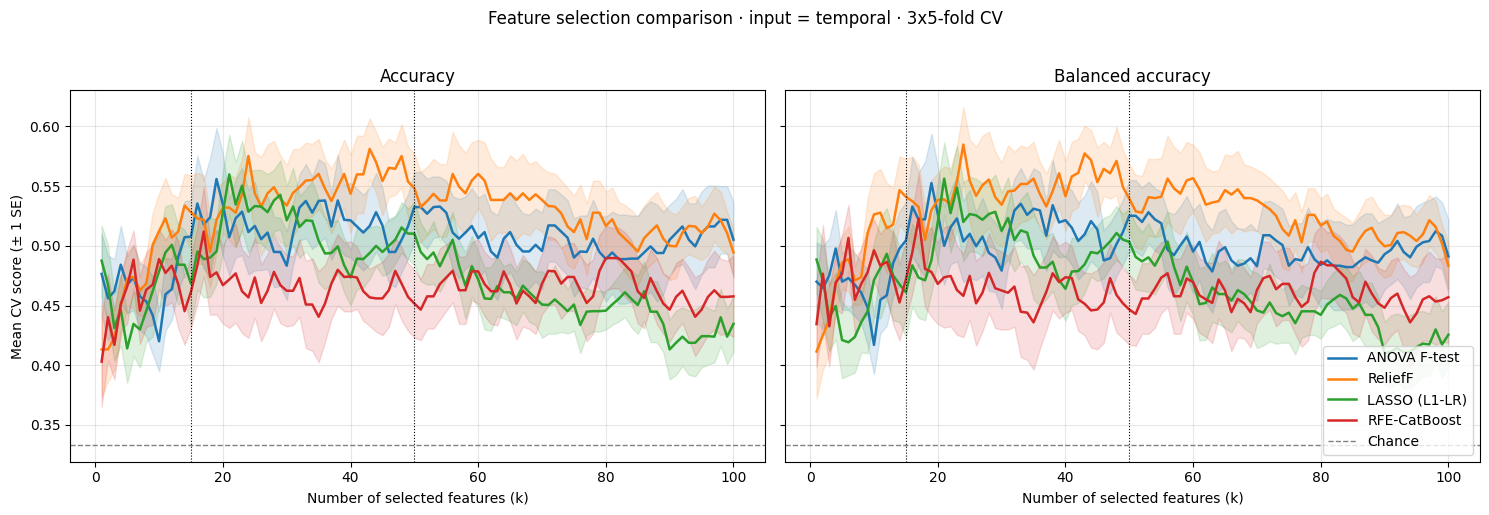

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
palette = dict(zip(Config.METHODS, sns.color_palette('tab10', len(Config.METHODS))))
for ax, (met, title) in zip(axes, [('acc', 'Accuracy'), ('bacc', 'Balanced accuracy')]):
    for m in Config.METHODS:
        g = summary[summary.method == m]
        se = g[f'{met}_std'] / np.sqrt(n_splits_total)
        ax.plot(g.k, g[f'{met}_mean'], label=METHOD_LABELS[m], color=palette[m], lw=1.8)
        ax.fill_between(g.k, g[f'{met}_mean'] - se, g[f'{met}_mean'] + se, color=palette[m], alpha=0.15)
    ax.axhline(chance, ls='--', c='gray', lw=1, label='Chance')
    ax.axvline(15, ls=':', c='k', lw=0.8); ax.axvline(50, ls=':', c='k', lw=0.8)
    ax.set_xlabel('Number of selected features (k)'); ax.set_title(title)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Mean CV score (± 1 SE)')
axes[1].legend(loc='lower right')
plt.suptitle(f'Feature selection comparison · input = {Config.FEATURE_MODE} · '
             f'{Config.N_REPEATS}x{Config.N_SPLITS}-fold CV', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(Config.OUT_DIR, f'{Config.FEATURE_MODE}_fs_curves.png'), dpi=200, bbox_inches='tight')
plt.show()

## 9. Σταθερότητα επιλογής (stability)

Αν μια μέθοδος διαλέγει εντελώς διαφορετικές πρωτεΐνες σε κάθε fold, οι "βιοδείκτες" της δεν είναι αξιόπιστοι, όσο καλή κι αν είναι η accuracy.
Μετράμε τη μέση **Jaccard ομοιότητα** των top-k συνόλων ανάμεσα σε όλα τα ζεύγη folds (1 = ίδια σύνολα, 0 = καμία κοινή).

In [ ]:
def mean_jaccard(sets):
    pairs = list(itertools.combinations(sets, 2))
    return np.mean([len(a & b) / len(a | b) for a, b in pairs])

stab_rows = []
for m in Config.METHODS:
    for k in [5, 10, 15, 25, 50, 100]:
        if k > K_MAX: continue
        sets = [set(r[:k]) for r in rankings[m]]
        stab_rows.append(dict(method=m, k=k, jaccard=mean_jaccard(sets)))
stab = pd.DataFrame(stab_rows)
stab.to_csv(os.path.join(Config.OUT_DIR, f'{Config.FEATURE_MODE}_fs_stability.csv'), index=False)
display(stab.pivot(index='method', columns='k', values='jaccard').round(3))

k,5,10,15,25,50,100
method,,,,,,
anova,0.171,0.215,0.201,0.229,0.265,0.337
lasso,0.148,0.194,0.190,0.219,0.253,0.313
relieff,0.159,0.235,0.272,0.310,0.328,0.405
rfe_cbr,0.123,0.181,0.201,0.204,0.246,0.277


## 10. Ποιες πρωτεΐνες επιλέγονται συχνότερα (στο best k κάθε μεθόδου)

In [ ]:
freq_tables = {}
for _, r in best_k_df.iterrows():
    m, k = r['method'], int(r['best_k'])
    counts = pd.Series(np.concatenate([rk[:k] for rk in rankings[m]])).value_counts()
    df = pd.DataFrame({'feature': feature_names[counts.index],
                       'selected_in_folds': counts.values,
                       'frequency': counts.values / len(rankings[m])})
    df.to_csv(os.path.join(Config.OUT_DIR, f'{Config.FEATURE_MODE}_fs_frequency_{m}_k{k}.csv'), index=False)
    freq_tables[m] = df
    print(f"\n{METHOD_LABELS[m]} · k = {k} (best k) · top 15 πιο σταθερά features")
    display(df.head(15))

# Επικάλυψη των σταθερών features (freq >= 0.8) ανάμεσα στις μεθόδους
stable_sets = {m: set(d.loc[d.frequency >= 0.8, 'feature']) for m, d in freq_tables.items()}
overlap = pd.DataFrame([[len(stable_sets[a] & stable_sets[b]) for b in stable_sets] for a in stable_sets],
                       index=stable_sets.keys(), columns=stable_sets.keys())
print("\nΚοινά σταθερά features (freq >= 0.8) ανά ζεύγος μεθόδων:")
display(overlap)


ReliefF · k = 44 (best k) · top 15 πιο σταθερά features


,feature,selected_in_folds,frequency
0,MMP12_T0,15,1.000000
1,ITGAV_T1,15,1.000000
2,AREG_T0,15,1.000000
3,PRKRA_T0,15,1.000000
4,APBB1IP_T1,14,0.933333
5,L1CAM_T1,14,0.933333
6,FEN1_T1,14,0.933333
7,ITGAV_T0,13,0.866667
8,SMOC1_T1,13,0.866667
9,NFKBIE_T1,13,0.866667



LASSO (L1-LR) · k = 23 (best k) · top 15 πιο σταθερά features


,feature,selected_in_folds,frequency
0,MMP12_T0,14,0.933333
1,AREG_T0,14,0.933333
2,EPS8L2_T0,11,0.733333
3,L1CAM_T1,11,0.733333
4,TP53_T1,11,0.733333
5,LTA4H_T0,10,0.666667
6,KLK10_T1,10,0.666667
7,SMOC1_T1,9,0.600000
8,OGFR_T1,8,0.533333
9,AMIGO2_T1,8,0.533333



RFE-CatBoost · k = 17 (best k) · top 15 πιο σταθερά features


,feature,selected_in_folds,frequency
0,MMP12_T0,15,1.000000
1,L1CAM_T1,13,0.866667
2,TP53_T1,11,0.733333
3,LYAR_T0,11,0.733333
4,CREG1_T1,9,0.600000
5,MMP12_T1,7,0.466667
6,SORCS2_T0,7,0.466667
7,KLK6_T0,7,0.466667
8,STX4_T0,6,0.400000
9,TXNDC15_T1,6,0.400000



ANOVA F-test · k = 18 (best k) · top 15 πιο σταθερά features


,feature,selected_in_folds,frequency
0,AREG_T0,14,0.933333
1,MMP12_T0,14,0.933333
2,L1CAM_T1,13,0.866667
3,TP53_T1,13,0.866667
4,ITGAV_T1,11,0.733333
5,MMP12_T1,8,0.533333
6,ITGAV_T0,7,0.466667
7,INPP1_T1,7,0.466667
8,HS6ST1_T0,7,0.466667
9,OGFR_T1,7,0.466667



Κοινά σταθερά features (freq >= 0.8) ανά ζεύγος μεθόδων:


,relieff,lasso,rfe_cbr,anova
relieff,16,2,2,4
lasso,2,2,1,2
rfe_cbr,2,1,2,2
anova,4,2,2,4


## 11. Αποτελέσματα στο format της διπλωματικής (Mean / Std / Fold_i)

In [ ]:
fmt_rows = []
for _, r in best_k_df.iterrows():
    m, k = r['method'], int(r['best_k'])
    g = raw[(raw.method == m) & (raw.k == k)].sort_values('split')
    row = {'Model': f"{METHOD_LABELS[m]} (k={k})",
           'Mean_Accuracy': g.accuracy.mean(), 'Std_Accuracy': g.accuracy.std(),
           'Mean_BalAcc': g.balanced_accuracy.mean(), 'Std_BalAcc': g.balanced_accuracy.std()}
    row.update({f'Fold_{i+1}': v for i, v in enumerate(g.accuracy.values)})
    fmt_rows.append(row)
thesis_fmt = pd.DataFrame(fmt_rows)
thesis_fmt.to_csv(os.path.join(Config.OUT_DIR, f'{Config.FEATURE_MODE}_fs_results_thesis_format.csv'), index=False)
display(thesis_fmt.round(4))
print("\nΌλα τα αρχεία στο:", Config.OUT_DIR)
for f in sorted(os.listdir(Config.OUT_DIR)): print("  ", f)

,Model,Mean_Accuracy,Std_Accuracy,Mean_BalAcc,Std_BalAcc,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5,Fold_6,Fold_7,Fold_8,Fold_9,Fold_10,Fold_11,Fold_12,Fold_13,Fold_14,Fold_15
0,ReliefF (k=44),0.5701,0.0983,0.5719,0.0975,0.6923,0.5385,0.5833,0.4167,0.7500,0.6154,0.5385,0.6667,0.6667,0.5833,0.4615,0.5385,0.4167,0.5833,0.5000
1,LASSO (L1-LR) (k=23),0.5504,0.1456,0.5489,0.1362,0.7692,0.3846,0.5833,0.5833,0.5833,0.6923,0.2308,0.7500,0.5833,0.5000,0.4615,0.3846,0.5000,0.6667,0.5833
2,RFE-CatBoost (k=17),0.5120,0.1445,0.5230,0.1465,0.4615,0.5385,0.6667,0.5000,0.7500,0.4615,0.3846,0.4167,0.6667,0.5000,0.3846,0.6154,0.1667,0.5833,0.5833
3,ANOVA F-test (k=18),0.5239,0.1927,0.5222,0.1872,0.3846,0.4615,0.5000,0.3333,0.9167,0.5385,0.5385,0.9167,0.6667,0.2500,0.4615,0.3077,0.5000,0.5000,0.5833



Όλα τα αρχεία στο: /content/fs_task1
   temporal_fs_best_k.csv
   temporal_fs_curve_raw.csv
   temporal_fs_curve_summary.csv
   temporal_fs_curves.png
   temporal_fs_frequency_anova_k18.csv
   temporal_fs_frequency_lasso_k23.csv
   temporal_fs_frequency_relieff_k44.csv
   temporal_fs_frequency_rfe_cbr_k17.csv
   temporal_fs_results_thesis_format.csv
   temporal_fs_stability.csv
   temporal_rankings_cache.pkl


## Σημειώσεις για την ερμηνεία

- Το **best k** που διαλέγουμε κοιτώντας την καμπύλη είναι ελαφρώς αισιόδοξο (επιλέγουμε το k με τα ίδια test folds). Για τελική αναφορά: nested CV όπου το k επιλέγεται στο εσωτερικό loop. Το **k_1se** (μικρότερο k μέσα σε 1 SE από το καλύτερο) είναι πιο λιτή εναλλακτική. Το best k διαλέγεται σε εξομαλυμένη καμπύλη (κινητός μέσος 5) για να μην κυνηγάμε θόρυβο.
- Τα δείγματα T00 έχουν T0 = T1, άρα στο `delta` mode είναι μηδενικά. Αυτό ισχύει και στη διπλωματική.
- Για να τρέξεις και τις τρεις αναπαραστάσεις: άλλαξε `Config.FEATURE_MODE` και ξανατρέξε από το βήμα 4 (κάθε mode έχει δικό του cache και δικά του αρχεία).